<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/homeworks/base/HW1_Regression_with_inference_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
%pip install -q ipywidgets "setuptools<81" "ydata-profiling==4.18.4" "scikit-learn==1.7.2" "pandas<3" "numpy<2.4"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder

random.seed(42)
np.random.seed(42)

/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/ipykernel_40519/65408184.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

`Your answer here`

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [3]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [ ] Отобразите 30 случайных строк тренировочного датасета.
- [ ] Отобразите первые 5 и последние 5 объектов тестового датасета
- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [ ] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [ ] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [ ] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [ ] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

In [4]:
display(df_train.sample(30, random_state=42))
display(df_test.head(5))
display(df_test.tail(5))

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6565,Renault KWID Climber 1.0 MT BSIV,2019,300000,35000,Petrol,Individual,Manual,First Owner,23.01 kmpl,999 CC,67 bhp,91Nm@ 4250rpm,5.0
2943,Maruti Wagon R LXI,2013,225000,58343,Petrol,Trustmark Dealer,Manual,First Owner,21.79 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0
2024,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
263,Hyundai i20 1.2 Asta,2010,300000,70000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1197 CC,80 bhp,"11.4 kgm at 4,000 rpm",5.0
4586,Skoda Octavia L and K 1.9 TDI MT,2005,250000,120000,Diesel,Individual,Manual,Third Owner,16.4 kmpl,1896 CC,90 bhp,"21.4@ 1,900(kgm@ rpm)",5.0
4479,Maruti Ciaz ZXi,2016,700000,20000,Petrol,Individual,Manual,First Owner,20.73 kmpl,1373 CC,91.1 bhp,130Nm@ 4000rpm,5.0
4881,Hyundai Grand i10 1.2 Kappa Magna BSIV,2017,445000,27000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
3583,Ford Ecosport 1.5 DV5 MT Trend,2016,515000,68609,Diesel,Dealer,Manual,First Owner,22.7 kmpl,1498 CC,89.84 bhp,204Nm@ 2000-2750rpm,5.0
6361,Hyundai Verna 1.4 VTVT,2014,500000,33400,Petrol,Individual,Manual,First Owner,17.43 kmpl,1396 CC,105.5 bhp,135.3Nm@ 5000rpm,5.0
4108,Hyundai i20 Era 1.2,2015,490000,45900,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Mahindra Xylo E4 BS IV,2010,229999,168000,Diesel,Individual,Manual,First Owner,14.0 kmpl,2498 CC,112 bhp,260 Nm at 1800-2200 rpm,7.0
1,Tata Nexon 1.5 Revotorq XE,2017,665000,25000,Diesel,Individual,Manual,First Owner,21.5 kmpl,1497 CC,108.5 bhp,260Nm@ 1500-2750rpm,5.0
2,Honda Civic 1.8 S AT,2007,175000,218463,Petrol,Individual,Automatic,First Owner,12.9 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0
3,Honda City i DTEC VX,2015,635000,173000,Diesel,Individual,Manual,First Owner,25.1 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0
4,Tata Indica Vista Aura 1.2 Safire BSIV,2011,130000,70000,Petrol,Individual,Manual,Second Owner,16.5 kmpl,1172 CC,65 bhp,96 Nm at 3000 rpm,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
995,Hyundai i10 Magna 1.1L,2008,250000,100000,Petrol,Individual,Manual,Second Owner,19.81 kmpl,1086 CC,68.05 bhp,99.04Nm@ 4500rpm,5.0
996,Hyundai i20 2015-2017 Sportz 1.2,2017,440000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
997,Hyundai i20 Era Diesel,2009,340000,40000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
998,Hyundai i10 Asta,2012,350000,25000,Petrol,Individual,Manual,First Owner,20.36 kmpl,1197 CC,78.9 bhp,111.8Nm@ 4000rpm,5.0
999,Honda City i DTec SV,2016,700000,110000,Diesel,Individual,Manual,First Owner,26.0 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0


In [5]:
for name, data in [("train", df_train), ("test", df_test)]:
    missing = data.isna().sum()
    print(name)
    print(missing[missing > 0])
    print("полных дублей", data.duplicated().sum())

train
mileage      202
engine       202
max_power    196
torque       203
seats        202
dtype: int64
полных дублей 985
test
mileage      19
engine       19
max_power    19
torque       19
seats        19
dtype: int64
полных дублей 62


по этим строкам видно как записана мощность и какие бывают типы топлива. сколько всего пропусков или какая цена типична по нескольким строкам врядли поймешь

если у двух строк разная цена то обычный `duplicated()` их пропустит. тут стоит сравнить отдельно признаки машины

In [6]:
profile = ProfileReport(df_train, title="машины в train", minimal=True, progress_bar=False)
profile.to_notebook_iframe()

  0%|          | 0/13 [00:00<?, ?it/s]

100%|██████████| 13/13 [00:00<00:00, 316.70it/s]

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [ ] Отобразите такие объекты (0.15 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


In [7]:
features = df_train.drop(columns="selling_price").columns.tolist()
repeated = df_train.duplicated(subset=features, keep=False)
print("строк в группах с повторами", repeated.sum())
display(df_train[repeated].sort_values(features))

rows_before = len(df_train)
df_train = df_train.drop_duplicates(subset=features, keep="first")
df_train = df_train.reset_index(drop=True)
print("удалено строк", rows_before - len(df_train))

строк в группах с повторами 1799


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1703,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
1836,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
117,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5637,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5652,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5753,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5991,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0


удалено строк 1159


In [8]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [9]:
for data in [df_train, df_test]:
    for column in ["mileage", "engine", "max_power"]:
        numbers = data[column].str.split().str[0]
        data[column] = pd.to_numeric(numbers, errors="coerce").astype(float)
    data.drop(columns="torque", inplace=True)

### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [10]:
missing_columns = ["mileage", "engine", "max_power", "seats"]
means_before = df_train[missing_columns].mean()
train_medians = df_train[missing_columns].median()

for column in missing_columns:
    df_train[column] = df_train[column].fillna(train_medians[column])
    df_test[column] = df_test[column].fillna(train_medians[column])

print("пропусков в train", df_train.isna().sum().sum())
print("пропусков в test", df_test.isna().sum().sum())

пропусков в train 0
пропусков в test 0


**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.

In [11]:
for data in [df_train, df_test]:
    data["engine"] = data["engine"].astype(int)
    data["seats"] = data["seats"].astype(int)

### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

In [12]:
for name, data in [("train", df_train), ("test", df_test)]:
    print(name)
    display(data.describe().round(2))
    display(data.describe(include="object"))

means = pd.DataFrame({"до заполнения": means_before,
                      "после заполнения": df_train[missing_columns].mean()})
display(means.round(2))

train


,year,selling_price,km_driven,mileage,engine,max_power,seats
count,5840.00,5840.00,5840.00,5840.00,5840.00,5840.00,5840.00
mean,2013.43,522960.09,73952.24,19.43,1429.45,87.91,5.43
std,4.10,535432.00,60071.14,3.99,485.66,31.64,0.98
min,1983.00,29999.00,1.00,0.00,624.00,0.00,2.00
25%,2011.00,250000.00,39000.00,16.95,1197.00,68.00,5.00
50%,2014.00,405000.00,70000.00,19.37,1248.00,81.86,5.00
75%,2017.00,640000.00,100000.00,22.30,1498.00,99.00,5.00
max,2020.00,10000000.00,2360457.00,42.00,3604.00,400.00,14.00


,name,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840,5840
unique,1924,4,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,91,3177,5223,5336,3603


test


,year,selling_price,km_driven,mileage,engine,max_power,seats
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,2013.68,617901.04,71393.34,19.34,1454.88,90.84,5.40
std,4.01,758553.86,48486.22,3.95,522.00,34.89,0.91
min,1995.00,31000.00,1303.00,0.00,624.00,34.20,4.00
25%,2011.00,250000.00,37000.00,16.55,1197.00,69.00,5.00
50%,2014.00,434999.00,61500.00,19.37,1248.00,82.42,5.00
75%,2017.00,670000.00,100000.00,22.30,1582.00,102.00,5.00
max,2020.00,6000000.00,375000.00,32.26,3604.00,280.00,9.00


,name,fuel,seller_type,transmission,owner
count,1000,1000,1000,1000,1000
unique,621,4,3,2,5
top,Maruti Alto 800 LXI,Diesel,Individual,Manual,First Owner
freq,15,534,837,877,623


,до заполнения,после заполнения
mileage,19.43,19.43
engine,1435.42,1429.45
max_power,88.10,87.91
seats,5.44,5.43


медианный год в обеих выборках 2014. медианная цена в train 405 тысяч а в test около 435 тысяч. в обеих выборках чаще всего встречаются дизель и механика. после заполнения пропусков средние значения признаков почти не изменились

In [13]:
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 6 (0.4 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

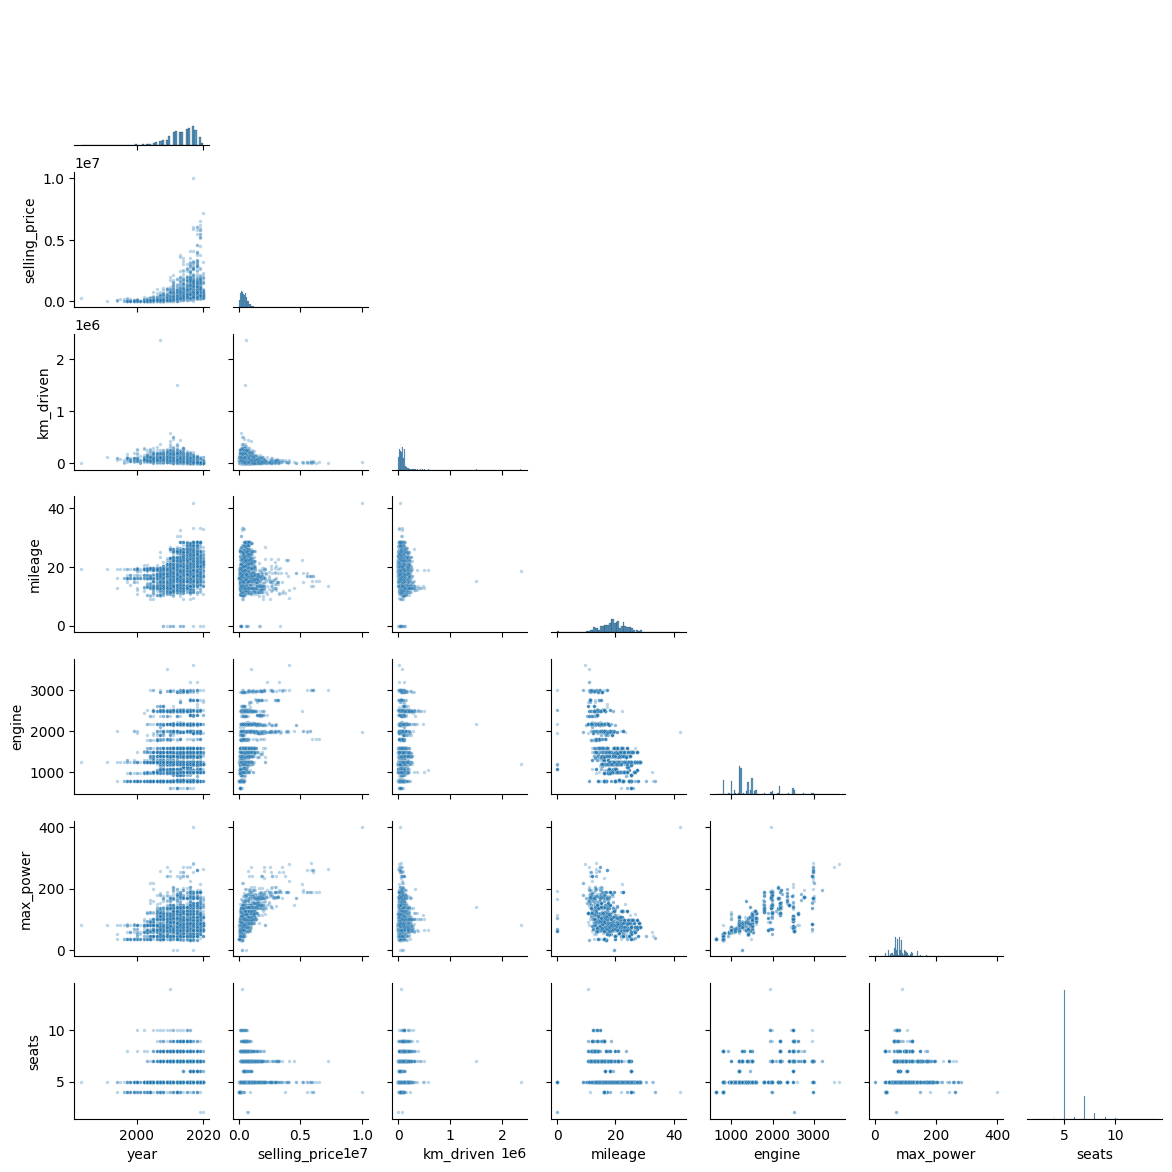

In [14]:
%matplotlib inline

sns.pairplot(df_train.select_dtypes(include="number"), corner=True, height=1.7,
             diag_kind="hist", plot_kws={"s": 6, "alpha": 0.3})
plt.show()

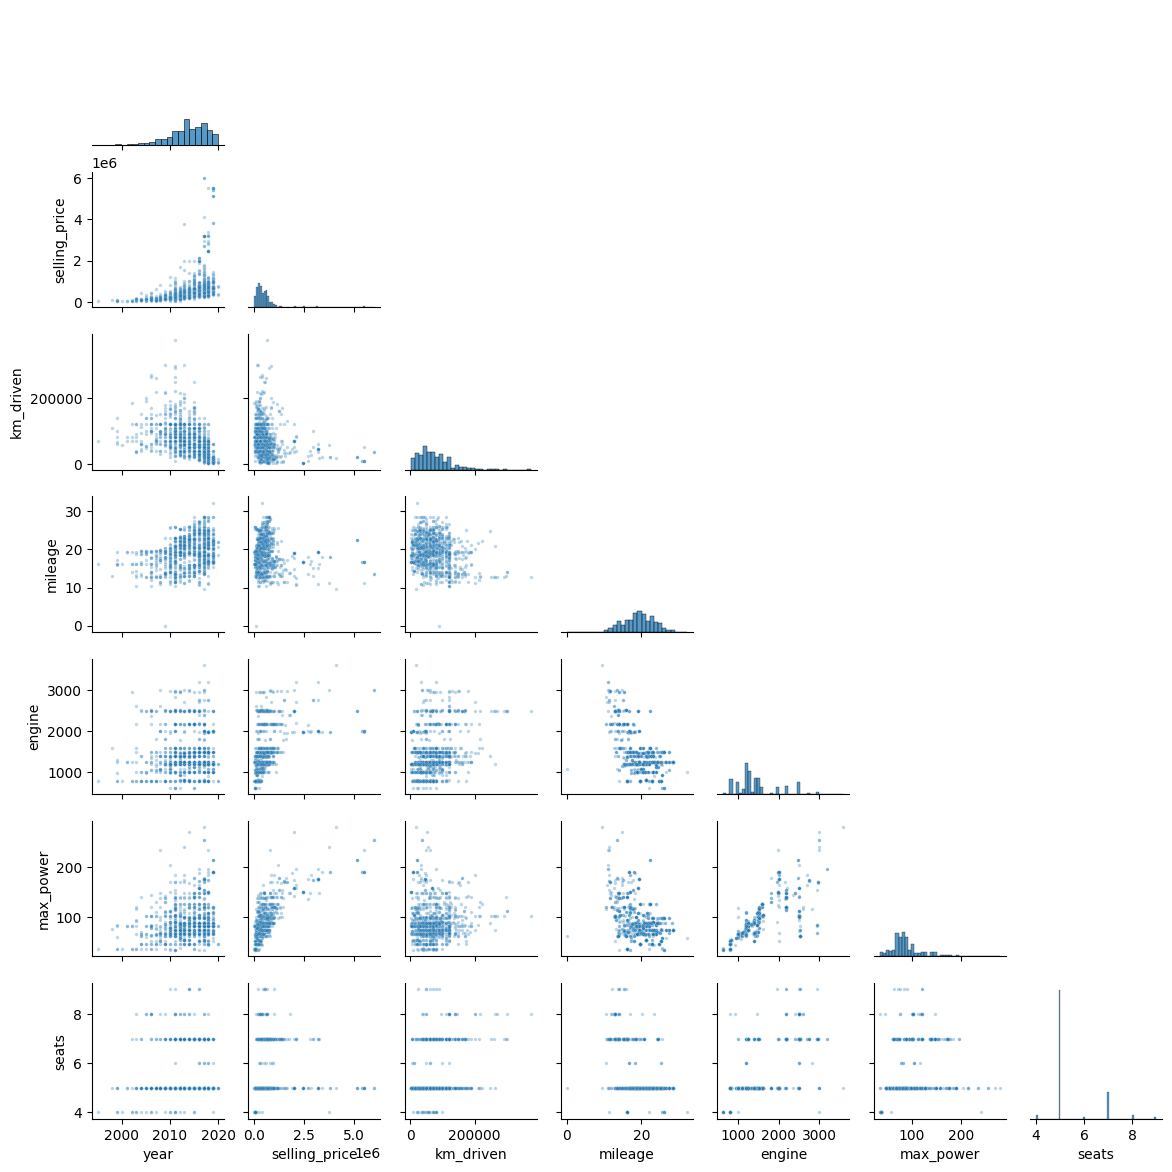

In [15]:
sns.pairplot(df_test.select_dtypes(include="number"), corner=True, height=1.7,
             diag_kind="hist", plot_kws={"s": 6, "alpha": 0.3})
plt.show()

более мощные машины обычно стоят дороже. похоже еще что у машин с большим мотором выше мощность

в test рисунок похож. но в train есть машина с пробегом больше 2 млн км а в test таких точек нет

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

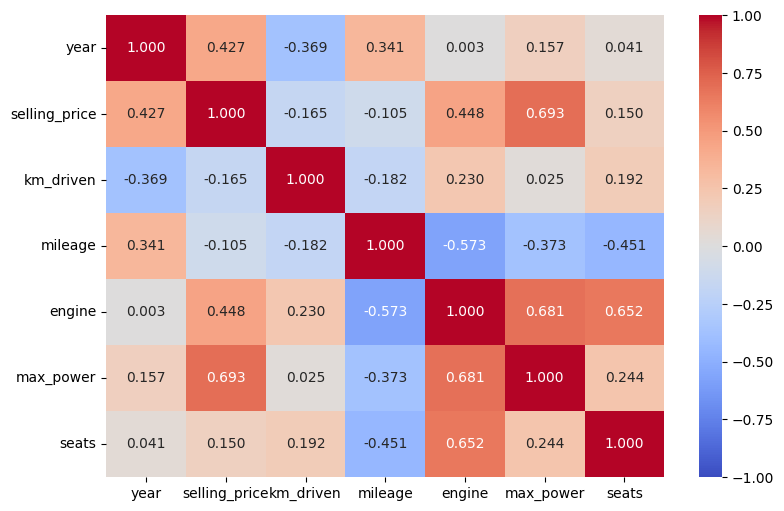

In [16]:
correlations = df_train.select_dtypes(include="number").corr(method="pearson")
plt.figure(figsize=(9, 6))
sns.heatmap(correlations, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.show()

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

ближе всего к нулю корреляция года и объема двигателя (0.003). у объема и мощности связь довольно сильная (0.68), у мощности и цены тоже (0.69)

у года и пробега корреляция -0.37. в среднем у старых машин пробег больше но по одному году пробег конкретной машины не угадаешь

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

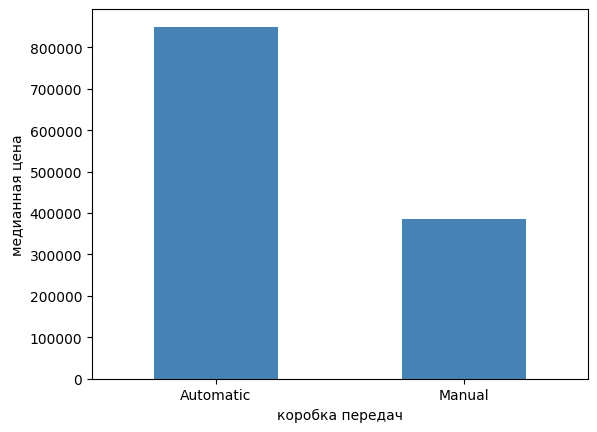

In [17]:
prices = df_train.groupby("transmission")["selling_price"].median()
prices.plot.bar(rot=0, color="steelblue")
plt.xlabel("коробка передач")
plt.ylabel("медианная цена")
plt.show()

у машин с автоматом медианная цена 850 тысяч а с механикой 386.5 тысяч. разница больше чем в два раза так что тип коробки стоит проверить как признак для модели

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [18]:
numeric_columns = ["year", "km_driven", "mileage", "engine", "max_power", "seats"]
X_train = df_train[numeric_columns].copy()
y_train = df_train["selling_price"]

год выпуска, пробег, пробег на единицу топлива, объем двигателя, мощность и число мест

In [19]:
X_test = df_test[numeric_columns].copy()
y_test = df_test["selling_price"]

### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [20]:
def show_scores(sample, actual, predicted):
    print(sample, "r2", round(r2_score(actual, predicted), 4))
    print(sample, "mse", round(MSE(actual, predicted)))

test_predictions = {}
linear = LinearRegression()
linear.fit(X_train, y_train)
test_predictions["линейная"] = linear.predict(X_test)
show_scores("train", y_train, linear.predict(X_train))
show_scores("test", y_test, test_predictions["линейная"])

train r2 0.5923
train mse 116874153930
test r2 0.5941
test mse 233298779730


по r^2 модель объясняет около 59% разброса цен и на трейне и на тесте. при этом mse на тесте почти в два раза больше

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

linear_scaled = LinearRegression()
linear_scaled.fit(X_train_scaled, y_train)
test_predictions["линейная со скейлингом"] = linear_scaled.predict(X_test_scaled)
show_scores("train", y_train, linear_scaled.predict(X_train_scaled))
show_scores("test", y_test, test_predictions["линейная со скейлингом"])

train r2 0.5923
train mse 116874153930
test r2 0.5941
test mse 233298779730


### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [22]:
weights = pd.Series(linear_scaled.coef_, index=numeric_columns)
display(weights.round())
print("самый большой вес по модулю у признака", weights.abs().idxmax())

year         152773.0
km_driven    -44159.0
mileage       28834.0
engine        61178.0
max_power    322807.0
seats        -23209.0
dtype: float64

самый большой вес по модулю у признака max_power


### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [23]:
lasso = Lasso()
lasso.fit(X_train_scaled, y_train)
test_predictions["lasso"] = lasso.predict(X_test_scaled)
show_scores("train", y_train, lasso.predict(X_train_scaled))
show_scores("test", y_test, test_predictions["lasso"])

train r2 0.5923
train mse 116874153940
test r2 0.5941
test mse 233299450599


In [24]:
lasso_weights = pd.Series(lasso.coef_, index=numeric_columns)
display(lasso_weights.round())
print("нулевых весов:", (lasso_weights == 0).sum())

year         152772.0
km_driven    -44158.0
mileage       28832.0
engine        61174.0
max_power    322808.0
seats        -23206.0
dtype: float64

нулевых весов: 0


у lasso на тесте r^2 такой же как у линейной регрессии при округлении до четырех знаков. при alpha = 1 штраф слишком маленький чтобы обнулить хотя бы один вес

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [25]:
from sklearn.pipeline import Pipeline

lasso_steps = Pipeline([("features", StandardScaler()), ("model", Lasso())])
lasso_grid = {"model__alpha": [0.1, 1, 10, 100, 500, 1000, 5000, 10000, 20000, 50000]}
lasso_search = GridSearchCV(lasso_steps, lasso_grid, cv=10, scoring="r2")
lasso_search.fit(X_train, y_train)

print("лучшие параметры:", lasso_search.best_params_)
test_predictions["lasso с подбором"] = lasso_search.predict(X_test)
show_scores("train", y_train, lasso_search.predict(X_train))
show_scores("test", y_test, test_predictions["lasso с подбором"])

лучшие параметры: {'model__alpha': 20000}
train r2 0.5852
train mse 118904192548
test r2 0.5715
test mse 246326384999


In [26]:
best_lasso = lasso_search.best_estimator_
weights = pd.Series(best_lasso.named_steps["model"].coef_, index=numeric_columns)
display(weights.round())
print("нулевых весов:", (weights == 0).sum())

year         149546.0
km_driven    -21457.0
mileage           0.0
engine         1487.0
max_power    326981.0
seats            -0.0
dtype: float64

нулевых весов: 2


10 значений alpha по 10 фолдов дают 100 обучений и еще одно на всем трейне. при alpha = 20000 обнулились веса mileage и seats

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [27]:
elastic_steps = Pipeline([("features", StandardScaler()), ("model", ElasticNet())])
elastic_grid = {"model__alpha": [0.001, 0.01, 0.1, 1, 10],
                "model__l1_ratio": [0.1, 0.5, 0.9]}
elastic_search = GridSearchCV(elastic_steps, elastic_grid, cv=10, scoring="r2")
elastic_search.fit(X_train, y_train)

print("лучшие параметры:", elastic_search.best_params_)
test_predictions["elasticnet"] = elastic_search.predict(X_test)
show_scores("train", y_train, elastic_search.predict(X_train))
show_scores("test", y_test, test_predictions["elasticnet"])

лучшие параметры: {'model__alpha': 1, 'model__l1_ratio': 0.9}
train r2 0.5884
train mse 117993441994
test r2 0.5722
test mse 245894595583


для elasticnet лучшие параметры по r^2 на фолдах это alpha = 1 и l1_ratio = 0.9. проверил 15 пар на 10 фолдах и еще раз обучил лучшую модель на всем train. всего 151 обучение

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Удалите из них столбец `name`

In [28]:
print("разных названий в train:", df_train["name"].nunique())
X_train_cat = df_train.drop(columns=["selling_price", "name"]).copy()
X_test_cat = df_test.drop(columns=["selling_price", "name"]).copy()

разных названий в train: 1924


В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.

In [29]:
assert X_train_cat.shape == (5840, 10)

In [30]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [31]:
from sklearn.compose import ColumnTransformer

numeric_ridge = ["year", "km_driven", "mileage", "engine", "max_power"]
category_columns = ["fuel", "seller_type", "transmission", "owner", "seats"]

features = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_ridge),
    ("categories", OneHotEncoder(drop="first", handle_unknown="ignore",
                                 sparse_output=False), category_columns)
], verbose_feature_names_out=False)

train_encoded = features.fit_transform(X_train_cat)
test_encoded = features.transform(X_test_cat)
display(pd.DataFrame(train_encoded, columns=features.get_feature_names_out()).head())
print("train:", train_encoded.shape, "test:", test_encoded.shape)

,year,km_driven,mileage,engine,max_power,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,...,owner_Test Drive Car,owner_Third Owner,seats_4,seats_5,seats_6,seats_7,seats_8,seats_9,seats_10,seats_14
0,0.139570,1.191152,0.995867,-0.373643,-0.439550,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.139570,0.766619,0.428830,0.141162,0.493513,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.837167,0.883158,0.895506,-0.068879,0.066175,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-1.569719,0.766619,-0.835712,-0.270682,0.009281,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.872122,-0.482007,0.177929,-0.478663,-0.191113,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


train: (5840, 23) test: (1000, 23)


### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [32]:
ridge_steps = Pipeline([("features", features), ("model", Ridge())])
ridge_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
ridge_search = GridSearchCV(ridge_steps, ridge_grid, cv=10, scoring="r2")
ridge_search.fit(X_train_cat, y_train)

best_ridge = ridge_search.best_estimator_
print("лучший alpha:", ridge_search.best_params_["model__alpha"])
test_predictions["ridge"] = best_ridge.predict(X_test_cat)
show_scores("train", y_train, best_ridge.predict(X_train_cat))
show_scores("test", y_test, test_predictions["ridge"])

/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/bokhyan_hw1_check.sWfWmXKkd7/env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/bokhyan_hw1_check.sWfWmXKkd7/env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/bokhyan_hw1_check.sWfWmXKkd7/env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/bokhyan_hw1_check.sWfWmXKkd7/env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


лучший alpha: 10
train r2 0.6538
train mse 99238428031
test r2 0.6455
test mse 203804808290


/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/bokhyan_hw1_check.sWfWmXKkd7/env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/var/folders/md/1cwdxcj9029gzv7mhg8hkg480000gn/T/bokhyan_hw1_check.sWfWmXKkd7/env/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


да. с категориями у ridge r^2 на тесте вырос с 0.5941 до 0.6455 а mse снизился с 233 до 204 млрд

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metric`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [33]:
def business_metric(y_true, y_pred):
    relative_error = abs(y_pred - y_true) / y_true
    return (relative_error <= 0.1).mean()

shares = {}
for name, prediction in test_predictions.items():
    shares[name] = business_metric(y_test, prediction)

display(pd.Series(shares, name="доля на тесте").sort_values(ascending=False))

ridge                     0.248
elasticnet                0.241
lasso с подбором          0.233
линейная                  0.227
линейная со скейлингом    0.227
lasso                     0.227
Name: доля на тесте, dtype: float64

лучше всего получился ridge. у 248 машин из 1000 ошибка по цене не больше 10%

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [34]:
import pickle

model_data = {
    "model": best_ridge,
    "medians": train_medians.to_dict(),
    "price_by_year": df_train.groupby("year")["selling_price"].median(),
    "price_by_transmission": df_train.groupby("transmission")["selling_price"].median()
}

with open("model.pickle", "wb") as file:
    pickle.dump(model_data, file)

In [35]:
with open("model.pickle", "rb") as file:
    saved = pickle.load(file)

car = X_test_cat.iloc[[0]]
price = saved["model"].predict(car)[0]
print("прогноз для первой машины из test", round(price), "рупий")

прогноз для первой машины из test 611352 рупий


# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.

[приложение в streamlit community cloud](https://perfectteatimer-ml-again-app-sufues.streamlit.app/)